<a href="https://colab.research.google.com/github/vaishnavi1407-rudr/Logistics-Delivery-Analysis/blob/main/Week1_Logistics_Delivery_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/logistics_delivery_data.csv')

df.head()

,order_id,order_date,distance_km,traffic_level,weather,vehicle_type,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,delivery_status
0,ORD0001,2026-01-17,61,Medium,Clear,Van,4899,115,95,137.09,On Time
1,ORD0002,2026-05-20,328,High,Clear,Truck,12673,372,401,789.80,Delayed
2,ORD0003,2026-04-28,482,High,Clear,Van,722,676,689,865.56,Delayed
3,ORD0004,2026-03-20,435,Medium,Clear,Van,6807,617,607,798.07,On Time
4,ORD0005,2026-03-19,140,Medium,Clear,Truck,12055,180,186,356.43,Delayed


In [4]:
print(df.shape)
print(df.columns)
print(df.info())

(500, 11)
Index(['order_id', 'order_date', 'distance_km', 'traffic_level', 'weather',
       'vehicle_type', 'order_value_inr', 'promised_delivery_minutes',
       'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   order_id                   500 non-null    object 
 1   order_date                 500 non-null    object 
 2   distance_km                500 non-null    int64  
 3   traffic_level              492 non-null    object 
 4   weather                    495 non-null    object 
 5   vehicle_type               500 non-null    object 
 6   order_value_inr            500 non-null    int64  
 7   promised_delivery_minutes  500 non-null    int64  
 8   actual_delivery_minutes    500 non-null    int64  
 9   delivery_cost_inr   

In [5]:
# 1. Display number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns)

# 3. Display data types and non-null values
print("\nDataset Information:")
df.info()

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (500, 11)

Column Names:
Index(['order_id', 'order_date', 'distance_km', 'traffic_level', 'weather',
       'vehicle_type', 'order_value_inr', 'promised_delivery_minutes',
       'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   order_id                   500 non-null    object 
 1   order_date                 500 non-null    object 
 2   distance_km                500 non-null    int64  
 3   traffic_level              492 non-null    object 
 4   weather                    495 non-null    object 
 5   vehicle_type               500 non-null    object 
 6   order_value_inr            500 non-null    int64  
 7   promised_delivery_minutes  500 non-null    int64  
 8   actual_delivery_minutes 

In [6]:
# 1. Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 2. Remove duplicate rows
df = df.drop_duplicates()

# 3. Handle missing categorical values
df["traffic_level"] = df["traffic_level"].fillna("Unknown")
df["weather"] = df["weather"].fillna("Unknown")

# 4. Fill missing delivery costs with median
df["delivery_cost_inr"] = df["delivery_cost_inr"].fillna(
    df["delivery_cost_inr"].median()
)

# 5. Convert order_date to datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# 6. Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# 7. Display final shape
print("\nCleaned dataset shape:", df.shape)

Duplicate rows: 0

Missing values after cleaning:
order_id                     0
order_date                   0
distance_km                  0
traffic_level                0
weather                      0
vehicle_type                 0
order_value_inr              0
promised_delivery_minutes    0
actual_delivery_minutes      0
delivery_cost_inr            0
delivery_status              0
dtype: int64

Cleaned dataset shape: (500, 11)


In [7]:
# 1. Total deliveries
total_deliveries = len(df)

# 2. On-time and delayed deliveries
on_time = (df["delivery_status"] == "On Time").sum()
delayed = (df["delivery_status"] == "Delayed").sum()

# 3. Calculate delivery rates
on_time_rate = (on_time / total_deliveries) * 100
delay_rate = (delayed / total_deliveries) * 100

# 4. Average delivery time
avg_delivery_time = df["actual_delivery_minutes"].mean()

# 5. Average delivery cost
avg_delivery_cost = df["delivery_cost_inr"].mean()

# 6. Display KPIs
print("Total Deliveries:", total_deliveries)
print("On-Time Deliveries:", on_time)
print("Delayed Deliveries:", delayed)
print("On-Time Delivery Rate:", round(on_time_rate, 2), "%")
print("Delivery Delay Rate:", round(delay_rate, 2), "%")
print("Average Delivery Time:", round(avg_delivery_time, 2), "minutes")
print("Average Delivery Cost:", round(avg_delivery_cost, 2), "INR")

Total Deliveries: 500
On-Time Deliveries: 235
Delayed Deliveries: 265
On-Time Delivery Rate: 47.0 %
Delivery Delay Rate: 53.0 %
Average Delivery Time: 422.44 minutes
Average Delivery Cost: 475.11 INR


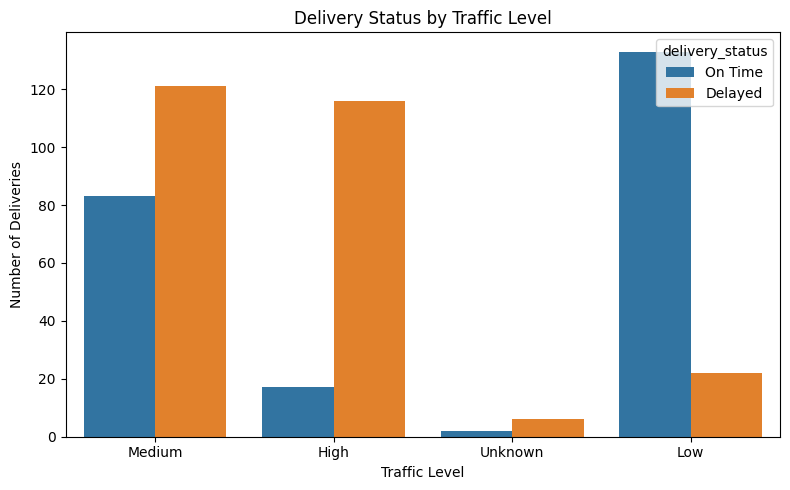

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="traffic_level",
    hue="delivery_status"
)

plt.title("Delivery Status by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()

In [9]:
traffic_delay = pd.crosstab(
    df["traffic_level"],
    df["delivery_status"],
    normalize="index"
) * 100

print(traffic_delay.round(2))

delivery_status  Delayed  On Time
traffic_level                    
High               87.22    12.78
Low                14.19    85.81
Medium             59.31    40.69
Unknown            75.00    25.00


In [10]:
# Calculate delivery status percentage by weather
weather_analysis = pd.crosstab(
    df["weather"],
    df["delivery_status"],
    normalize="index"
) * 100

print(weather_analysis.round(2))

delivery_status  Delayed  On Time
weather                          
Clear              43.65    56.35
Rain               64.06    35.94
Storm              88.64    11.36
Unknown            60.00    40.00


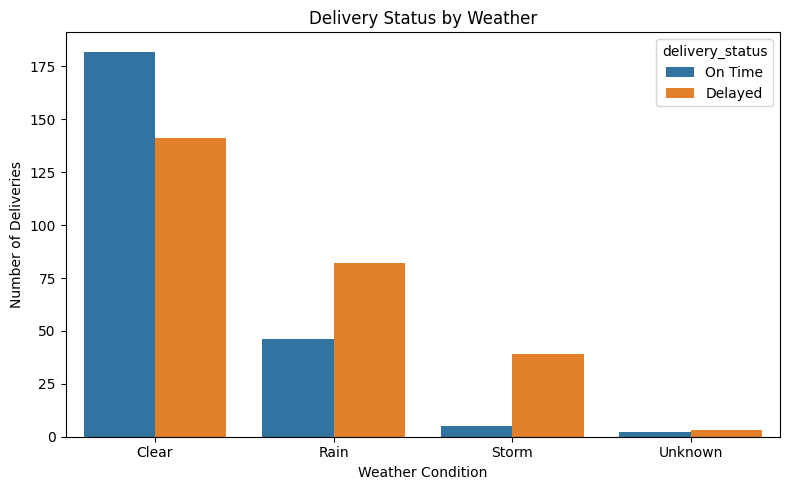

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="weather",
    hue="delivery_status"
)

plt.title("Delivery Status by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()

In [12]:
# Calculate delivery status percentage by vehicle type

vehicle_analysis = pd.crosstab(
    df["vehicle_type"],
    df["delivery_status"],
    normalize="index"
) * 100

print(vehicle_analysis.round(2))

delivery_status  Delayed  On Time
vehicle_type                     
Bike               50.81    49.19
Truck              55.15    44.85
Van                52.92    47.08


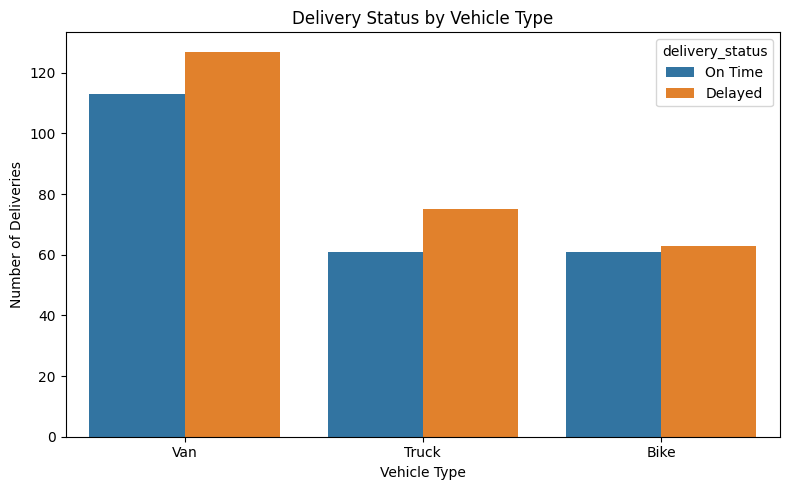

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="vehicle_type",
    hue="delivery_status"
)

plt.title("Delivery Status by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Deliveries")

plt.tight_layout()
plt.show()

In [14]:
# Convert order_date to datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# Extract month
df["month"] = df["order_date"].dt.to_period("M").astype(str)

# Calculate monthly delivery status percentages
monthly_analysis = pd.crosstab(
    df["month"],
    df["delivery_status"],
    normalize="index"
) * 100

print(monthly_analysis.round(2))

delivery_status  Delayed  On Time
month                            
2026-01            46.15    53.85
2026-02            61.33    38.67
2026-03            45.56    54.44
2026-04            54.55    45.45
2026-05            57.45    42.55
2026-06            54.79    45.21


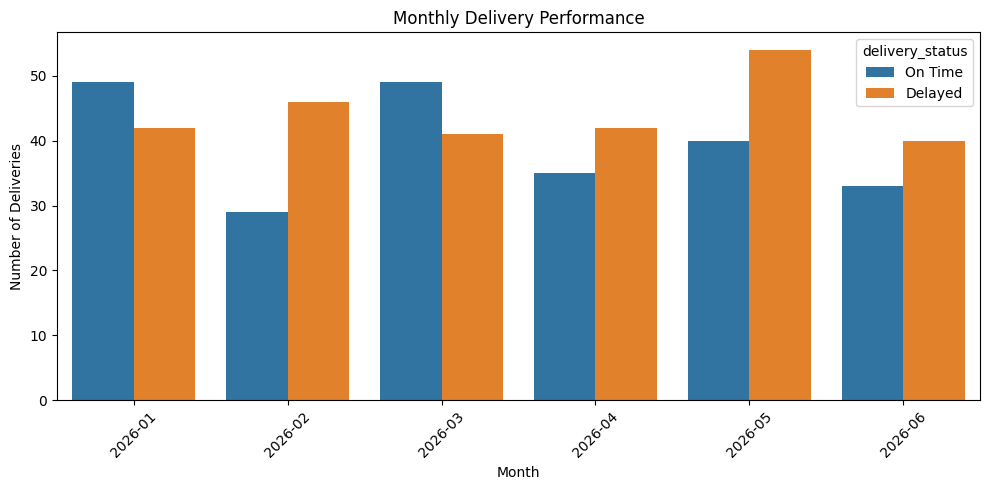

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="month",
    hue="delivery_status",
    order=sorted(df["month"].unique())
)

plt.title("Monthly Delivery Performance")
plt.xlabel("Month")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Create distance categories
df["distance_category"] = pd.cut(
    df["distance_km"],
    bins=[0, 100, 250, 500],
    labels=["Short", "Medium", "Long"],
    include_lowest=True
)

# Calculate delivery status percentage by distance
distance_analysis = pd.crosstab(
    df["distance_category"],
    df["delivery_status"],
    normalize="index"
) * 100

print(distance_analysis.round(2))

delivery_status    Delayed  On Time
distance_category                  
Short                40.95    59.05
Medium               56.15    43.85
Long                 56.23    43.77


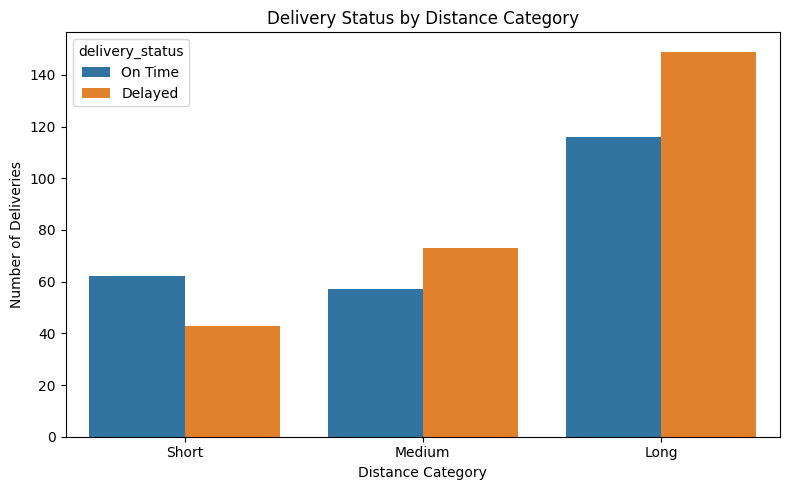

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="distance_category",
    hue="delivery_status",
    order=["Short", "Medium", "Long"]
)

plt.title("Delivery Status by Distance Category")
plt.xlabel("Distance Category")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()

In [18]:
# Calculate the difference between actual and promised delivery time
df["delay_minutes"] = (
    df["actual_delivery_minutes"]
    - df["promised_delivery_minutes"]
)

# Display sample records
print(df[
    [
        "order_id",
        "promised_delivery_minutes",
        "actual_delivery_minutes",
        "delay_minutes",
        "delivery_status"
    ]
].head(10))

  order_id  promised_delivery_minutes  actual_delivery_minutes  delay_minutes  \
0  ORD0001                        115                       95            -20   
1  ORD0002                        372                      401             29   
2  ORD0003                        676                      689             13   
3  ORD0004                        617                      607            -10   
4  ORD0005                        180                      186              6   
5  ORD0006                        330                      348             18   
6  ORD0007                        386                      387              1   
7  ORD0008                        166                      220             54   
8  ORD0009                        359                      374             15   
9  ORD0010                        187                      157            -30   

  delivery_status  
0         On Time  
1         Delayed  
2         Delayed  
3         On Time  
4       

In [20]:
# Calculate average delay by traffic level
avg_delay_by_traffic = (
    df.groupby("traffic_level")["delay_minutes"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_delay_by_traffic.round(2))

traffic_level
High       25.12
Unknown    12.62
Medium      3.22
Low       -18.52
Name: delay_minutes, dtype: float64


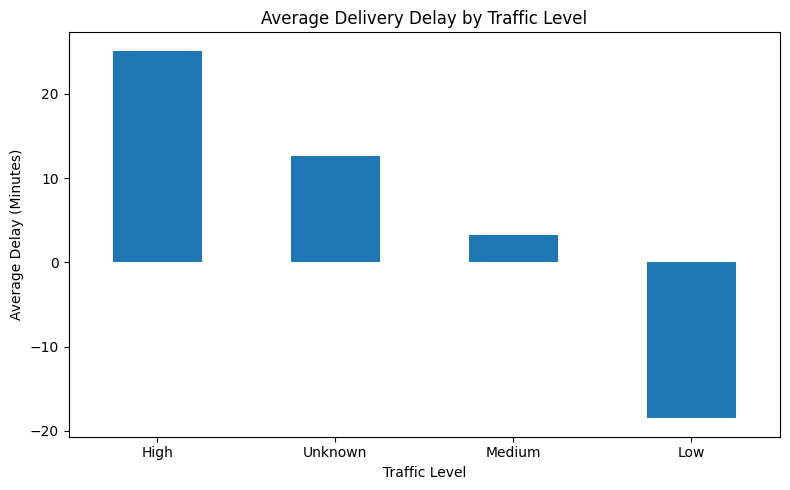

In [21]:
avg_delay_by_traffic.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Delivery Delay by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
# Average delay by weather condition
avg_delay_by_weather = (
    df.groupby("weather")["delay_minutes"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Delivery Delay by Weather:")
print(avg_delay_by_weather.round(2))

Average Delivery Delay by Weather:
weather
Storm      28.59
Unknown    18.00
Rain       10.38
Clear      -4.49
Name: delay_minutes, dtype: float64


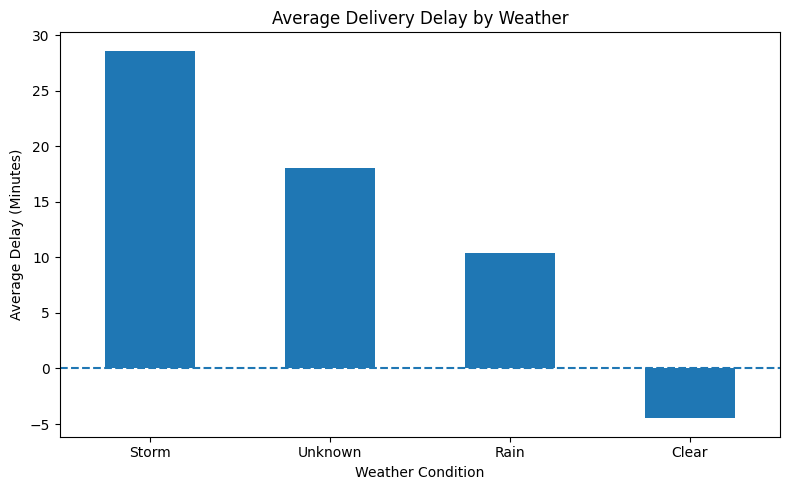

In [23]:
plt.figure(figsize=(8, 5))

avg_delay_by_weather.plot(kind="bar")

plt.title("Average Delivery Delay by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delay (Minutes)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
performance_analysis = df.groupby("delivery_status").agg(
    Total_Orders=("order_id", "count"),
    Average_Distance_KM=("distance_km", "mean"),
    Average_Delivery_Cost=("delivery_cost_inr", "mean"),
    Average_Actual_Time=("actual_delivery_minutes", "mean")
)

print(performance_analysis.round(2))

                 Total_Orders  Average_Distance_KM  Average_Delivery_Cost  \
delivery_status                                                             
Delayed                   265               266.26                 502.64   
On Time                   235               244.21                 444.06   

                 Average_Actual_Time  
delivery_status                       
Delayed                       448.53  
On Time                       393.02  


In [25]:
# KPI Summary Table

total_orders = len(df)

on_time_orders = (df["delivery_status"] == "On Time").sum()
delayed_orders = (df["delivery_status"] == "Delayed").sum()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Deliveries",
        "On-Time Deliveries",
        "Delayed Deliveries",
        "On-Time Delivery Rate (%)",
        "Delivery Delay Rate (%)",
        "Average Delivery Time (minutes)",
        "Average Delivery Cost (INR)"
    ],
    "Value": [
        total_orders,
        on_time_orders,
        delayed_orders,
        round(on_time_orders / total_orders * 100, 2),
        round(delayed_orders / total_orders * 100, 2),
        round(df["actual_delivery_minutes"].mean(), 2),
        round(df["delivery_cost_inr"].mean(), 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Deliveries,500.00
1,On-Time Deliveries,235.00
2,Delayed Deliveries,265.00
3,On-Time Delivery Rate (%),47.00
4,Delivery Delay Rate (%),53.00
5,Average Delivery Time (minutes),422.44
6,Average Delivery Cost (INR),475.11
